# Dự báo mực nước hồ thủy điện Sông Ba Hạ 

## 1. Cơ sở lý thuyết (tóm tắt)

### 1.1. Phương trình cân bằng nước hồ chứa
Thể tích nước trong hồ thay đổi theo thời gian bằng lượng nước vào trừ lượng nước ra:

$$\frac{dV}{dt} = Q_{đến}(t) - Q_{xả}(t) - E(t) - S(t)$$

- $Q_{đến}$: lưu lượng về hồ (m³/s) — cột `Q_ve`
- $Q_{xả}$: tổng lưu lượng xả qua máy và qua tràn (m³/s) — cột `Sigma_Qx` $= Q_{xt} + Q_{xm}$
- $E$: bốc hơi mặt hồ; $S$: thấm. Hai thành phần này nhỏ so với dòng chảy và **không có trong dữ liệu**, nên thường bỏ qua hoặc gộp vào sai số.

Rời rạc hóa theo bước giờ ($\Delta t = 3600$ s):

$$V_{t+1} = V_t + (Q_{đến,t} - Q_{xả,t})\cdot 3600$$

### 1.2. Quan hệ Z–V (đường đặc tính hồ chứa)
Mực nước $Z$ (m) và thể tích $V$ (m³) liên hệ qua đường cong $V = f(Z)$ (hoặc $Z = f^{-1}(V)$) do thiết kế/khảo sát lòng hồ cung cấp. Khi có đường Z–V, ta tính $V_{t+1}$ từ cân bằng nước rồi đổi ngược ra $Z_{t+1}$. 
**Dữ liệu hiện có không chứa đường Z–V**, vì vậy ở bước 4.6 ta chỉ ước lượng *thực nghiệm* diện tích mặt hồ hiệu dụng $A$ từ chính dữ liệu ($\Delta Z \approx \Delta V / A$), và ghi rõ đó là xấp xỉ.

### 1.3. Ràng buộc vận hành
$$MNC \le Z \le MNDBT \quad (101{,}0\ \text{m} \le Z \le 105{,}0\ \text{m})$$
Khi lũ lớn, mực nước có thể tạm vượt MNDBT (dữ liệu có max ≈ 105,96 m); đây là hiện tượng thật, không phải lỗi.

### 1.4. Ý tưởng dự báo
Mực nước hôm nay thay đổi *chậm* (quán tính lớn), nên mô hình đơn giản nhất — **Persistence** ($\hat Z_{t+h} = Z_t$) — đã khá mạnh. Mọi mô hình phức tạp phải **thắng được Persistence** mới có giá trị. Vì vậy ta sẽ dự báo cả *mực nước* $Z_{t+h}$ lẫn *độ thay đổi* $\Delta Z = Z_{t+h} - Z_t$.

## 2. Cấu hình và đọc dữ liệu

In [18]:
# Thư viện 
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Cấu hình 
DATA_PATH = "raw_data_sbh.csv"      # đường dẫn file dữ liệu
FIG_DIR   = "figs"                  # thư mục lưu biểu đồ
os.makedirs(FIG_DIR, exist_ok=True)

MNC, MNDBT = 101.0, 105.0           # mực nước chết, mực nước dâng bình thường (m) — khớp cột H_c, H_dbt
MAX_INTERP_HOURS = 6                # chỉ nội suy khoảng thiếu tối đa 6 giờ
HORIZONS = [1, 6, 24, 72, 168]      # các hạn dự báo (giờ): 1h, 6h, 1 ngày, 3 ngày, 7 ngày
TRAIN_END = "2023-12-31 23:00"      # train: 2022–2023
VAL_END   = "2024-12-31 23:00"      # validation: 2024;  test: 2025

In [19]:
raw = pd.read_csv(DATA_PATH, parse_dates=["time"], encoding="utf-8-sig").set_index("time")

raw = raw.rename(columns={
    "Temperature (°C)": "Temp", "Humidity (%)": "Humid", "Precipitations (mm)": "Rain",
    "Wind_speeds (km/h)": "WindSp", "Wind_direction (°)": "WindDir",
    "Cloud_cover_mid (%)": "Cloud", "Pressure (hPa)": "Press",
    "Soil_moisture_0_7cm (m³/m³)": "SoilM"})
raw = raw.drop(columns=["ten_ho"]) 

print("Kích thước:", raw.shape)
print("Từ", raw.index.min(), "đến", raw.index.max())
print("Bước thời gian duy nhất:", raw.index.to_series().diff().dropna().unique())
raw.head()

Kích thước: (35064, 17)
Từ 2022-01-01 00:00:00 đến 2025-12-31 23:00:00
Bước thời gian duy nhất: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[ns]


,H_tl,H_dbt,H_c,Q_ve,Sigma_Qx,Q_xt,Q_xm,N_cxs,N_cxm,Temp,Humid,Rain,WindSp,WindDir,Cloud,Press,SoilM
time,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,104.94,105.0,101.0,410.0,450.0,50.0,400.0,0.0,1.0,20.33,87.29,0.03,9.27,60.86,24.71,1019.44,0.44
2022-01-01 01:00:00,104.93,105.0,101.0,405.0,450.0,50.0,400.0,0.0,1.0,20.43,87.14,0.06,9.47,52.71,33.57,1018.64,0.44
2022-01-01 02:00:00,104.93,105.0,101.0,415.0,450.0,50.0,400.0,0.0,1.0,20.24,87.57,0.06,8.77,51.71,20.57,1017.74,0.44
2022-01-01 03:00:00,104.92,105.0,101.0,420.0,450.0,50.0,400.0,0.0,1.0,20.34,87.29,0.00,8.79,47.29,34.86,1017.09,0.44
2022-01-01 04:00:00,104.92,105.0,101.0,425.0,450.0,50.0,400.0,0.0,1.0,20.14,88.43,0.00,8.16,57.71,23.86,1017.03,0.44


## 3. Tiền xử lý

### 3.1. Kiểm tra giá trị thiếu
Dữ liệu ban đầu có 35.064 bản ghi theo giờ trong giai đoạn 2022–2025. Qua kiểm tra, các biến thủy văn có khoảng 158–159 giá trị thiếu, chiếm khoảng 0,45% tổng số quan sát. Trong khi đó, các biến khí tượng không xuất hiện giá trị thiếu.

Các khoảng thiếu chủ yếu kéo dài 1 giờ, tuy nhiên vẫn xuất hiện một số khoảng thiếu liên tục từ 8 đến 18 giờ. Nghiên cứu sử dụng phương pháp nội suy tuyến tính theo thời gian đối với các biến liên tục và phương pháp điền tiến đối với các biến rời rạc, giới hạn tối đa 6 giờ. Những khoảng thiếu dài hơn được giữ nguyên để tránh tạo ra dữ liệu không có căn cứ.

In [20]:
print(raw.isnull().sum())

H_tl        158
H_dbt       158
H_c         158
Q_ve        158
Sigma_Qx    158
Q_xt        159
Q_xm        159
N_cxs       158
N_cxm       158
Temp          0
Humid         0
Rain          0
WindSp        0
WindDir       0
Cloud         0
Press         0
SoilM         0
dtype: int64


In [21]:
def gap_report(s):
    """Liệt kê các đoạn NaN liên tục của một chuỗi: thời điểm bắt đầu và độ dài (giờ)."""
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    runs = isna.groupby(grp).agg(["first", "size"])
    starts = s.index.to_series().groupby(grp).first()
    out = pd.DataFrame({"bat_dau": starts, "so_gio": runs["size"]})[runs["first"]]
    return out.reset_index(drop=True)

gaps = gap_report(raw["H_tl"])
print(f"Tổng số giờ thiếu H_tl: {raw['H_tl'].isna().sum()}  ({raw['H_tl'].isna().mean():.2%})")
print("Phân bố độ dài đoạn thiếu (giờ):")
print(gaps["so_gio"].value_counts().sort_index().to_string())
print("\nCác đoạn thiếu dài hơn 6 giờ:")
print(gaps[gaps["so_gio"] > MAX_INTERP_HOURS].to_string(index=False))

Tổng số giờ thiếu H_tl: 158  (0.45%)
Phân bố độ dài đoạn thiếu (giờ):
so_gio
1     78
2      1
6      1
8      1
13     1
16     1
17     1
18     1

Các đoạn thiếu dài hơn 6 giờ:
            bat_dau  so_gio
2023-03-23 08:00:00      16
2024-04-07 11:00:00      13
2024-08-12 07:00:00      17
2024-10-19 06:00:00      18
2025-10-16 16:00:00       8


### 3.2. Phát hiện và xử lý ngoại lai
Quy tắc dựa trên **vật lý**: mực nước hồ không thể thấp hơn MNC quá 1 m (hồ không được vận hành dưới MNC), và không thể nhảy hàng chục mét trong 1 giờ. Các giá trị như 2,68 m hay 37,2 m là lỗi cảm biến/nhập liệu. 
Giá trị > MNDBT (tối đa 105,96 m) thì **giữ lại** vì có thể là mực nước thật trong lũ.

In [22]:
df = raw.copy()

# H_tl thấp hơn (MNC - 1 m) -> lỗi
bad_low  = df["H_tl"] < (MNC - 1.0)
# H_tl cao hơn MNDBT + 3 m -> nghi lỗi 
bad_high = df["H_tl"] > (MNDBT + 3.0)
print("Số giá trị H_tl bị coi là ngoại lai (thấp):", bad_low.sum())
print("Số giá trị H_tl bị coi là ngoại lai (cao):", bad_high.sum())
print(df.loc[bad_low, "H_tl"].to_string())

df.loc[bad_low | bad_high, "H_tl"] = np.nan

# Lưu lượng không âm
for c in ["Q_ve", "Sigma_Qx", "Q_xt", "Q_xm"]:
    n_neg = (df[c] < 0).sum()
    if n_neg:
        print(f"{c}: {n_neg} giá trị âm -> NaN")
        df.loc[df[c] < 0, c] = np.nan

Số giá trị H_tl bị coi là ngoại lai (thấp): 10
Số giá trị H_tl bị coi là ngoại lai (cao): 0
time
2024-05-15 01:00:00    37.20
2024-05-15 02:00:00    37.20
2024-05-15 03:00:00    37.20
2024-05-15 04:00:00    37.20
2024-05-15 05:00:00    37.20
2024-05-15 06:00:00    37.20
2024-05-15 07:00:00    37.80
2024-07-11 19:00:00     2.68
2024-08-18 12:00:00    10.94
2025-10-10 04:00:00    10.24


### 3.3. Nội suy giá trị thiếu
- Biến liên tục (mực nước, lưu lượng): **nội suy tuyến tính theo thời gian**, chỉ cho khoảng thiếu ≤ 6 giờ.
- Biến rời rạc (số tổ máy N_cxs, N_cxm): điền tiến (ffill) tối đa 6 giờ.
- Khoảng thiếu dài hơn 6 giờ: **để nguyên NaN** và bỏ các mẫu liên quan khi huấn luyện (không bịa số liệu).

In [23]:
def fill_short_gaps(s, max_gap=MAX_INTERP_HOURS, method="interp"):
    """Chỉ điền các đoạn thiếu <= max_gap giờ; đoạn dài hơn giữ nguyên NaN hoàn toàn."""
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    gap_len = isna.groupby(grp).transform("sum")      # độ dài của đoạn NaN chứa từng điểm
    if method == "interp":
        filled = s.interpolate(method="time", limit_area="inside")   # nội suy tuyến tính
    else:
        filled = s.ffill()                                           # điền tiến cho biến rời rạc
    short_gap = isna & (gap_len <= max_gap)           # chỉ những điểm NaN thuộc đoạn ngắn
    return s.where(~short_gap, filled)

cont_cols = ["H_tl", "Q_ve", "Sigma_Qx", "Q_xt", "Q_xm"]
disc_cols = ["N_cxs", "N_cxm"]

for c in cont_cols:
    df[c] = fill_short_gaps(df[c], method="interp")
for c in disc_cols:
    df[c] = fill_short_gaps(df[c], method="ffill")

# Cột H_dbt, H_c là hằng số -> điền lại bằng giá trị cấu hình cho đầy đủ
df["H_dbt"], df["H_c"] = MNDBT, MNC

print("Còn thiếu sau xử lý:")
print(df[cont_cols + disc_cols].isna().sum().to_string())

Còn thiếu sau xử lý:
H_tl        79
Q_ve        72
Sigma_Qx    72
Q_xt        72
Q_xm        72
N_cxs       72
N_cxm       72


## 4. Phân tích khám phá (EDA)

### 4.1. Chuỗi thời gian tổng quan

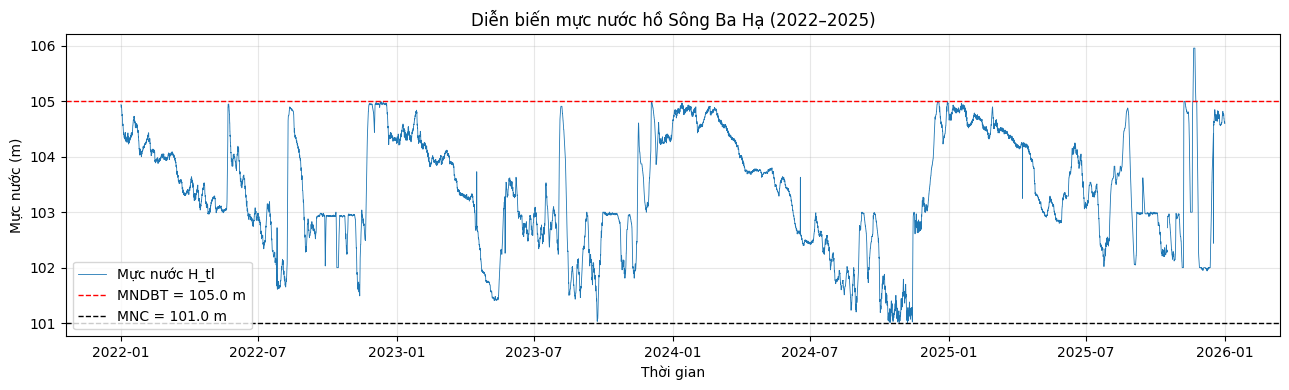

In [24]:
plt.figure(figsize=(13, 4))

plt.plot(df.index, df["H_tl"],
         lw=0.6,
         color="tab:blue",
         label="Mực nước H_tl")

plt.axhline(MNDBT, color="red", ls="--",
            lw=1, label=f"MNDBT = {MNDBT} m")    

plt.axhline(MNC, color="black", ls="--",
            lw=1, label=f"MNC = {MNC} m")

plt.xlabel("Thời gian")
plt.ylabel("Mực nước (m)")
plt.title("Diễn biến mực nước hồ Sông Ba Hạ (2022–2025)")

plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2. Tính mùa
Xem trung bình theo tháng để biết lúc nào hồ cao/thấp và khi nào nước về nhiều (mùa lũ).

        H_tl    Q_ve  Rain_mm_gio
time                             
1     104.61  107.17         0.06
2     104.36   60.23         0.05
3     104.06   44.15         0.06
4     103.41   44.11         0.04
5     103.08   64.56         0.21
6     103.19   87.49         0.21
7     102.66  129.64         0.23
8     102.99  221.75         0.21
9     102.58  449.42         0.37
10    102.36  439.68         0.33
11    103.06  815.21         0.30
12    104.20  295.19         0.17


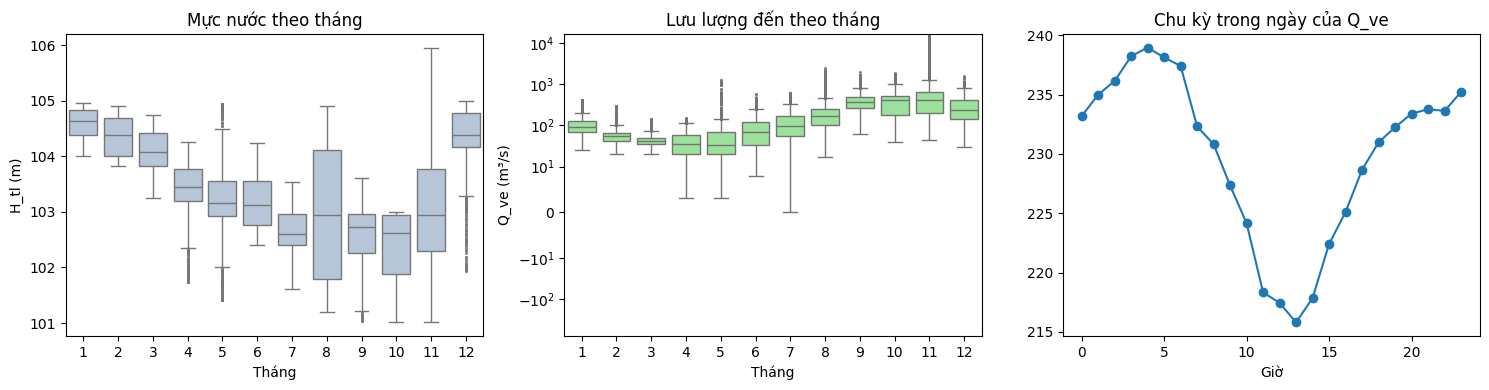

In [25]:
monthly = df.groupby(df.index.month).agg(H_tl=("H_tl", "mean"), Q_ve=("Q_ve", "mean"),
                                           Rain_mm_gio=("Rain", "mean")).round(2)
print(monthly.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df.index.month, y=df["H_tl"], ax=axes[0], color="lightsteelblue", fliersize=1)
axes[0].set_title("Mực nước theo tháng"); axes[0].set_xlabel("Tháng"); axes[0].set_ylabel("H_tl (m)")
sns.boxplot(x=df.index.month, y=df["Q_ve"], ax=axes[1], color="lightgreen", fliersize=1)
axes[1].set_yscale("symlog", linthresh=10); axes[1].set_title("Lưu lượng đến theo tháng"); axes[1].set_xlabel("Tháng"); axes[1].set_ylabel("Q_ve (m³/s)")
df["Q_ve"].groupby(df.index.hour).mean().plot(ax=axes[2], marker="o"); axes[2].set_title("Chu kỳ trong ngày của Q_ve"); axes[2].set_xlabel("Giờ")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda2_seasonality.png"); plt.show()

* Đối với mực nước thượng lưu (H_tl), mực nước có xu hướng giảm từ đầu năm đến khoảng tháng 7, sau đó biến động trong các tháng tiếp theo và tăng trở lại vào tháng 12. Một số tháng có mức độ phân tán dữ liệu lớn, phản ánh sự biến động đáng kể của mực nước.<br>
* lưu lượng đến tập trung vào các tháng cuối năm (cao nhất khoảng tháng 11), còn mực nước thường thấp ở khoảng tháng 9–10 (hồ hạ thấp để đón lũ) rồi dâng lên tháng 11–1. Dựa vào đó ta định nghĩa **mùa lũ = tháng 9–12**, mùa kiệt = các tháng còn lại; sau này sẽ đánh giá sai số riêng cho từng mùa.<br>
* Xét theo chu kỳ trong ngày, lưu lượng nước đến hồ có xu hướng tăng vào đầu ngày, giảm dần trong buổi sáng và đầu giờ chiều, sau đó tăng trở lại vào buổi chiều và tối.

In [27]:
# PHÂN TÍCH MÙA LŨ VÀ NGOÀI MÙA LŨ
# 1. Xác định các tháng mùa lũ
FLOOD_MONTHS = [9, 10, 11, 12]
# 2. Tạo cột phân loại mùa lũ
df["is_flood"] = df.index.month.isin(FLOOD_MONTHS).astype(int)
# 3. Thống kê mực nước, lưu lượng đến và lưu lượng xả
result = df.groupby("is_flood")[
    ["H_tl", "Q_ve", "Sigma_Qx"]
].agg(["mean", "std", "max", "min"]).round(2)
# 4. Hiển thị kết quả
# 0 = Ngoài mùa lũ | 1 = Mùa lũ
print(result.to_string())

            H_tl                          Q_ve                        Sigma_Qx                      
            mean   std     max     min    mean     std      max   min     mean     std      max  min
is_flood                                                                                            
0         103.54  0.92  104.97  101.20   95.49  115.30   2478.0   0.0    99.62  137.10    900.0  0.0
1         103.05  1.10  105.96  101.01  497.83  906.84  16160.0  30.0   479.11  863.54  16100.0  0.0


- Lưu lượng nước đến hồ (Q_ve): Mùa lũ có lưu lượng trung bình cao gấp 5,21 lần ngoài mùa lũ, đồng thời biến động mạnh hơn đáng kể.
- Mực nước thượng lưu (H_tl): Mực nước trung bình mùa lũ thấp hơn ngoài mùa lũ 0,48 m, nhưng giá trị lớn nhất và mức độ biến động đều cao hơn.

Nhìn chung: Mùa lũ có lưu lượng nước đến hồ tăng mạnh (trung bình 497,74 m³/s), trong khi mực nước trung bình không tăng mà còn thấp hơn ngoài mùa lũ. Điều này liên quan đến hoạt động điều tiết của hồ chứa: lưu lượng xả trung bình mùa lũ đạt 479,03 m³/s, cao gấp khoảng 4,81 lần so với ngoài mùa lũ, gần bằng lượng nước đến, nên phần lớn nước về được xả đi thay vì tích lại trong hồ.

### 4.3. Tương quan giữa các biến

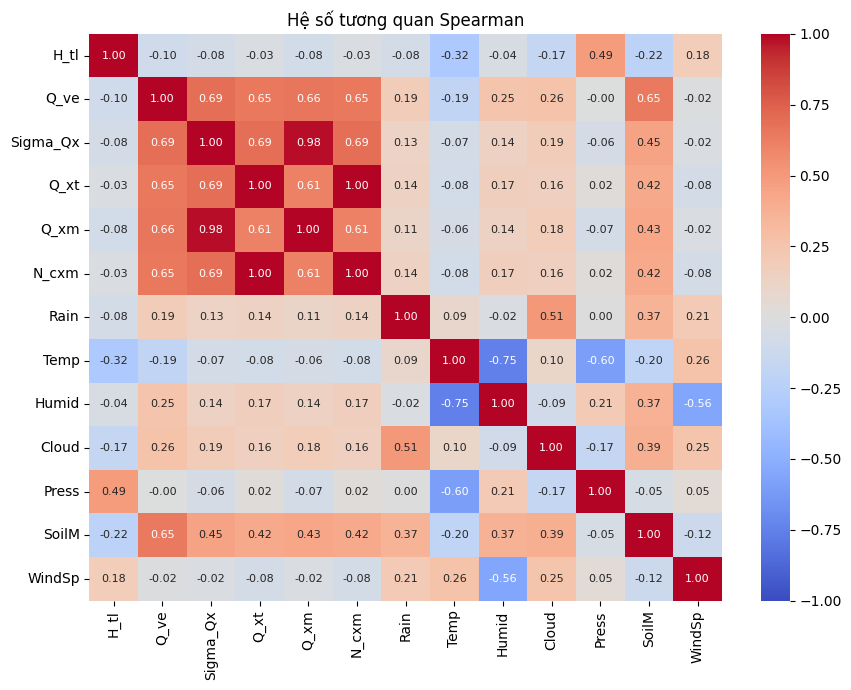

In [28]:
cols_corr = ["H_tl", "Q_ve", "Sigma_Qx", "Q_xt", "Q_xm", "N_cxm", "Rain", "Temp", "Humid",
             "Cloud", "Press", "SoilM", "WindSp"]
# Dùng Spearman vì lưu lượng lệch rất mạnh (lũ), Pearson sẽ bị vài giá trị cực lớn chi phối
corr = df[cols_corr].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Hệ số tương quan Spearman"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda3_corr.png"); plt.show()

nhóm biến khí tượng, Temp và Humid(độ ẩm không khí) có mối tương quan nghịch mạnh với hệ số -0.75, trong khi Rain và Cloud có tương quan thuận ở mức trung bình với hệ số 0.51.

Xét mối tương quan với biến mục tiêu H_tl, Press có hệ số tương quan thuận cao nhất (0.49), tiếp theo là Temp với hệ số tương quan nghịch (-0.32). Các biến còn lại có mức tương quan tương đối thấp. Tuy nhiên, điều này không đồng nghĩa với việc các biến có tương quan thấp không ảnh hưởng đến mực nước hồ, bởi sự biến động mực nước còn phụ thuộc vào quá trình tích lũy và điều tiết lưu lượng theo thời gian.

### 4.4. Mưa → lưu lượng về hồ: độ trễ
Mưa không làm nước về hồ ngay; có độ trễ do dòng chảy trên lưu vực. Ta thử tương quan giữa **tổng mưa 24 giờ** và `Q_ve` dịch theo nhiều độ trễ. (Chú ý: mưa ở đây là mưa trung bình tại một điểm khí tượng, chỉ là chỉ báo thô của mưa trên cả lưu vực.)

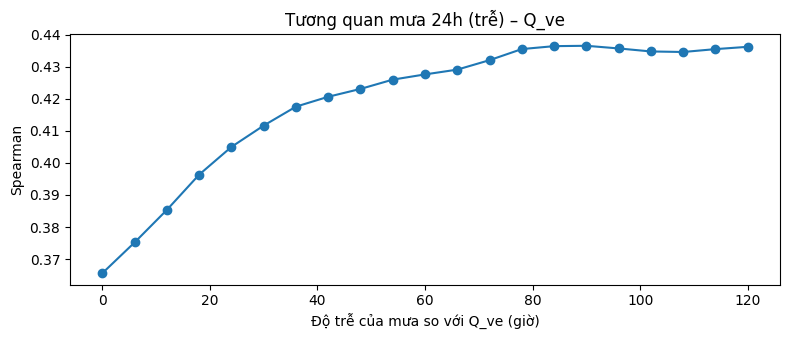

Độ trễ có tương quan lớn nhất: 90 giờ, rho = 0.436


In [29]:
rain24 = df["Rain"].rolling(24).sum()
lags = list(range(0, 121, 6))
cc = [rain24.shift(l).corr(df["Q_ve"], method="spearman") for l in lags]
plt.figure(figsize=(8, 3.5))
plt.plot(lags, cc, marker="o"); plt.xlabel("Độ trễ của mưa so với Q_ve (giờ)")
plt.ylabel("Spearman"); plt.title("Tương quan mưa 24h (trễ) – Q_ve")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda4_rain_lag.png"); plt.show()
print("Độ trễ có tương quan lớn nhất:", lags[int(np.argmax(cc))], "giờ, rho =", round(max(cc), 3))

Kết quả cho thấy hệ số tương quan có xu hướng tăng dần theo độ trễ thời gian, từ khoảng 0.366 tại thời điểm 0 giờ lên khoảng 0.437 tại khoảng 88–120 giờ. Đặc biệt, từ khoảng 80 giờ trở đi, hệ số tương quan gần như ổn định.

Kết quả này cho thấy lượng mưa trong quá khứ có mối liên hệ với lưu lượng nước về hồ, đồng thời phản ánh khả năng tồn tại độ trễ trong quá trình hình thành và tập trung dòng chảy của lưu vực. Do đó, việc xây dựng các đặc trưng lượng mưa trễ và lượng mưa tích lũy theo nhiều khoảng thời gian có thể giúp cung cấp thêm thông tin cho mô hình dự đoán.

### 4.5. Tự tương quan của mực nước
Cho biết mực nước "nhớ" quá khứ bao lâu → gợi ý chọn các lag đưa vào mô hình.

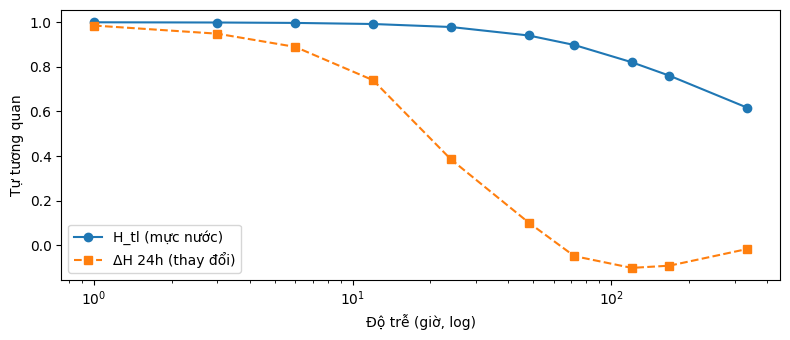

 lag_gio  ACF_H_tl
       1     1.000
       3     0.999
       6     0.997
      12     0.992
      24     0.979
      48     0.940
      72     0.898
     120     0.821
     168     0.760
     336     0.617


In [30]:
h = df["H_tl"]
lag_list = [1, 3, 6, 12, 24, 48, 72, 120, 168, 336]
acf_level = [h.autocorr(l) for l in lag_list]
acf_diff  = [h.diff(24).autocorr(l) for l in lag_list]   # thay đổi theo ngày
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lag_list, acf_level, "o-", label="H_tl (mực nước)")
ax.plot(lag_list, acf_diff, "s--", label="ΔH 24h (thay đổi)")
ax.set_xscale("log"); ax.set_xlabel("Độ trễ (giờ, log)"); ax.set_ylabel("Tự tương quan"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda5_acf.png"); plt.show()
print(pd.DataFrame({"lag_gio": lag_list, "ACF_H_tl": np.round(acf_level, 3)}).to_string(index=False))

chuỗi mực nước hồ H_tl có mức độ tự tương quan rất cao. Cụ thể, hệ số ACF đạt 1.000 tại độ trễ 1 giờ và vẫn duy trì ở mức 0.979 tại độ trễ 24 giờ. Khi khoảng thời gian trễ tăng lên, hệ số tương quan giảm dần, đạt 0.761 tại 168 giờ và 0.618 tại 336 giờ.

Kết quả này cho thấy mực nước hồ có tính liên tục và phụ thuộc đáng kể vào trạng thái trong quá khứ. Đặc biệt, thông tin mực nước trong các khoảng thời gian gần có khả năng cung cấp giá trị dự đoán cao cho các thời điểm tiếp theo. Do đó, việc xây dựng các đặc trưng trễ từ biến H_tl là cần thiết trong quá trình Feature Engineering nhằm cải thiện khả năng dự đoán của mô hình.

### 4.6. Kiểm tra cân bằng nước bằng dữ liệu (không cần đường Z–V)
Nếu cân bằng nước đúng thì $\Delta Z \propto (Q_{đến} - Q_{xả})$ với hệ số $1/A$ ($A$: diện tích mặt hồ hiệu dụng). 
>  Đây chỉ là **ước lượng xấp xỉ** từ dữ liệu, không thay thế đường Z–V thật.
> Nếu quan hệ rất chặt (R² cao) thì `Q_ve` nhiều khả năng được **tính ngược từ cân bằng nước** chứ không phải đo độc lập. Điều cần kiểm tra là nó khớp với mực nước đã đổi *tới thời điểm t* hay mực nước *sau t*. Kiểm tra riêng cho thấy `Q_ve` trung bình 6 giờ khớp nhất (Spearman ≈ 0,94) với thay đổi mực nước trong chính 6 giờ đó, và giảm nhanh khi dịch sang tương lai. Nghĩa là dùng `Q_ve` ở các giờ **≤ t** là hợp lệ, nhưng tuyệt đối không dùng `Q_ve` của giờ sau t.

Số ngày dùng: 1454
Diện tích mặt hồ hiệu dụng ước lượng A ≈ 44.47 km²  (R² = 0.83)  <- chỉ là ước lượng thực nghiệm


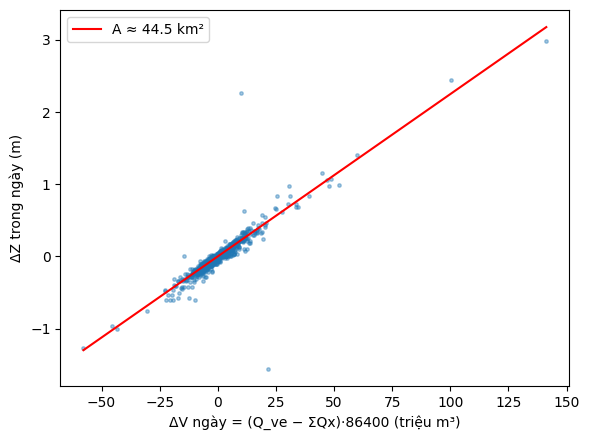

In [31]:
d = pd.DataFrame({
    "H": df["H_tl"].resample("D").last(),
    "net": (df["Q_ve"] - df["Sigma_Qx"]).resample("D").mean(),   # m3/s, trung bình ngày
}).dropna()
d["dH"] = d["H"].diff()                      # thay đổi mực nước trong ngày (23h hôm nay − 23h hôm qua)
d["dV"] = d["net"] * 86400                    # m3 trong 1 ngày
d = d.dropna()

# Chỉ dùng ngày hồ không xả tràn lớn để quan hệ ổn định (mực nước ≤ MNDBT)
dd = d[(d["H"] < MNDBT)]
slope = (dd["dH"] * dd["dV"]).sum() / (dd["dV"] ** 2).sum()    # hồi quy qua gốc: dH = slope * dV
A_eff = 1 / slope
r2 = np.corrcoef(dd["dV"], dd["dH"])[0, 1] ** 2
print(f"Số ngày dùng: {len(dd)}")
print(f"Diện tích mặt hồ hiệu dụng ước lượng A ≈ {A_eff/1e6:.2f} km²  (R² = {r2:.2f})  <- chỉ là ước lượng thực nghiệm")

plt.figure(figsize=(6, 4.5))
plt.scatter(dd["dV"] / 1e6, dd["dH"], s=6, alpha=0.4)
xs = np.linspace(dd["dV"].min(), dd["dV"].max(), 50)
plt.plot(xs / 1e6, slope * xs, "r-", label=f"A ≈ {A_eff/1e6:.1f} km²")
plt.xlabel("ΔV ngày = (Q_ve − ΣQx)·86400 (triệu m³)"); plt.ylabel("ΔZ trong ngày (m)"); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda6_waterbalance.png"); plt.show()

Kết quả kiểm tra cân bằng nước thông qua dữ liệu cho thấy tồn tại mối quan hệ tuyến tính thuận giữa chênh lệch lưu lượng nước vào và lưu lượng nước ra với sự thay đổi mực nước hồ theo ngày. Phần lớn các điểm dữ liệu phân bố tương đối sát đường hồi quy tuyến tính, cho thấy biến động mực nước có xu hướng phù hợp với nguyên lý cân bằng nước của hồ chứa.

Dựa trên mô hình hồi quy và giả định diện tích mặt hồ tương đối ổn định trong khoảng mực nước khảo sát, diện tích mặt hồ hiệu dụng được ước tính khoảng 44,5 km². Kết quả này cung cấp cơ sở định lượng để đánh giá tính hợp lý của dữ liệu lưu lượng và mực nước khi không có đường quan hệ mực nước – dung tích (Z–V).

Tuy nhiên, một số điểm dữ liệu có độ lệch đáng kể so với đường hồi quy. Điều này có thể liên quan đến sự thay đổi diện tích mặt hồ theo mực nước, sai số đo đạc, các thành phần cân bằng nước chưa được xem xét hoặc sự khác biệt về thời điểm ghi nhận dữ liệu

## 5. Tạo đặc trưng (feature engineering) và chia dữ liệu theo thời gian

**Nguyên tắc chống rò rỉ thông tin:** tại thời điểm dự báo $t$, chỉ được dùng thông tin có ở thời điểm $\le t$. Vì vậy mọi đặc trưng là **trễ (lag)** hoặc **thống kê trượt của quá khứ**.

- Đặc trưng trễ: `H_tl`, `Q_ve`, `Sigma_Qx` ở các độ trễ 1, 2, 3, 6, 12, 24, 48, 72, 168 giờ.
- Thống kê trượt: tổng mưa 6/24/72/168 giờ, trung bình `Q_ve` 24/72 giờ.
- Mùa vụ: giờ, tháng dạng sin/cos (để mô hình hiểu tính chu kỳ), cờ mùa lũ.
- Mục tiêu: $Z_{t+h}$ (và $\Delta Z = Z_{t+h} - Z_t$).

In [32]:
def make_features(data: pd.DataFrame, horizon: int) -> pd.DataFrame:
    """Tạo bảng đặc trưng X và mục tiêu y cho hạn dự báo `horizon` (giờ).
    Mọi đặc trưng chỉ dùng thông tin tại thời điểm t hoặc trước đó."""
    f = pd.DataFrame(index=data.index)
    lag_set = [1, 2, 3, 6, 12, 24, 48, 72, 168]

    f["H_now"] = data["H_tl"]            # mực nước hiện tại
    for col in ["H_tl", "Q_ve", "Sigma_Qx"]:
        for l in lag_set:
            f[f"{col}_lag{l}"] = data[col].shift(l)
    f["Q_ve_now"] = data["Q_ve"]
    f["Qx_now"] = data["Sigma_Qx"]

    # Thay đổi mực nước gần đây (xu hướng)
    for l in [1, 6, 24]:
        f[f"dH_{l}"] = data["H_tl"] - data["H_tl"].shift(l)

    # Thống kê trượt của quá khứ
    for w in [6, 24, 72, 168]:
        f[f"Rain_sum{w}"] = data["Rain"].rolling(w).sum()
    for w in [24, 72]:
        f[f"Qve_mean{w}"] = data["Q_ve"].rolling(w).mean()
    f["SoilM"] = data["SoilM"]
    f["Humid"] = data["Humid"]
    f["N_cxm"] = data["N_cxm"]

    # Mùa vụ (sin/cos giúp "tháng 12" nằm cạnh "tháng 1")
    f["hour_sin"] = np.sin(2 * np.pi * data.index.hour / 24)
    f["hour_cos"] = np.cos(2 * np.pi * data.index.hour / 24)
    f["month_sin"] = np.sin(2 * np.pi * data.index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * data.index.month / 12)
    f["is_flood"] = data["is_flood"]

    # Mục tiêu
    f["y_level"] = data["H_tl"].shift(-horizon)                # Z(t+h)
    f["y_delta"] = f["y_level"] - f["H_now"]                   # ΔZ = Z(t+h) - Z(t)
    return f

def split_by_time(feat: pd.DataFrame, horizon: int):
    """Chia train/val/test THEO THỜI GIAN (không xáo trộn), bỏ mẫu có NaN.
    Có khoảng 'purge' = horizon giờ ở cuối train/val để mục tiêu (t+h) không lọt sang tập sau."""
    feat = feat.dropna()
    t_tr, t_va = pd.Timestamp(TRAIN_END), pd.Timestamp(VAL_END)
    h = pd.Timedelta(hours=horizon)
    train = feat[feat.index + h <= t_tr]
    val   = feat[(feat.index > t_tr) & (feat.index + h <= t_va)]
    test  = feat[feat.index > t_va]
    return train, val, test

rows = []
datasets = {}
for hz in HORIZONS:
    ft = make_features(df, hz)
    tr, va, te = split_by_time(ft, hz)
    datasets[hz] = (tr, va, te)
    rows.append({"horizon_h": hz, "n_features": ft.shape[1] - 2,
                 "train": len(tr), "val": len(va), "test": len(te),
                 "train_from": tr.index.min().date(), "test_to": te.index.max().date()})
print(pd.DataFrame(rows).to_string(index=False))

 horizon_h  n_features  train  val  test train_from    test_to
         1          47  17246 8420  8670 2022-01-08 2025-12-31
         6          47  17236 8395  8660 2022-01-08 2025-12-31
        24          47  17208 8346  8640 2022-01-08 2025-12-30
        72          47  17160 8298  8592 2022-01-08 2025-12-28
       168          47  17064 8202  8496 2022-01-08 2025-12-24


### Kiểm tra nhanh: Persistence (baseline đơn giản nhất)
Dự báo $\hat Z_{t+h} = Z_t$ trên tập test. Đây là "ngưỡng" mà mọi mô hình sau này phải vượt qua.

In [33]:
def nse(obs, sim):
    """Nash–Sutcliffe Efficiency: 1 = hoàn hảo; 0 = ngang dự báo bằng trung bình; <0 = tệ hơn trung bình."""
    obs, sim = np.asarray(obs), np.asarray(sim)
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)

res = []
for hz in HORIZONS:
    te = datasets[hz][2]
    obs, sim = te["y_level"], te["H_now"]
    err = obs - sim
    res.append({"horizon_h": hz, "RMSE": np.sqrt((err ** 2).mean()), "MAE": err.abs().mean(), "NSE": nse(obs, sim)})
print("Persistence trên tập test (2025):")
print(pd.DataFrame(res).round(3).to_string(index=False))

Persistence trên tập test (2025):
 horizon_h  RMSE   MAE   NSE
         1 0.038 0.008 0.998
         6 0.102 0.039 0.988
        24 0.261 0.112 0.919
        72 0.565 0.288 0.619
       168 0.862 0.510 0.098
